In [55]:
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI
from typing import TypedDict, Annotated
from langchain_core.messages import HumanMessage, BaseMessage, AIMessage
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface.embeddings import HuggingFaceEmbeddings
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode,tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langgraph.types import interrupt,Command
import requests
import math
import os

In [53]:
load_dotenv()

True

In [54]:
endpoint = os.environ["AZURE_OPENAI_ENDPOINT"]
api_key = os.environ["AZURE_OPENAI_API_KEY"]
deployment = os.environ["AZURE_OPENAI_DEPLOYMENT_NAME"]

model = ChatOpenAI(
    model=deployment,
    base_url=f"{endpoint}/openai/v1/",
    api_key=api_key
)

In [28]:
loader=PyPDFLoader("Asmar_Resume2026.pdf")
docs=loader.load()

In [29]:
docs

[Document(metadata={'producer': 'pdfTeX-1.40.27', 'creator': 'LaTeX with hyperref', 'creationdate': '2026-10-23T19:00:39+00:00', 'author': '', 'keywords': '', 'moddate': '2026-10-23T19:00:39+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'Asmar_Resume2026.pdf', 'total_pages': 1, 'page': 0, 'page_label': '1'}, page_content='Md Asmar\nBhubaneswar, Odisha\n+91 8825237173|mdasmar719@gmail.com|LinkedIn|GitHub\nProfessional Summary\nComputer Science undergraduate with8.88 CGP Aand building AI-powered applications using Python,\nLangchain, Langgraph, Azure OpenAI, Google Gemini, Pinecone, ChromaDB, Flask and Streamlit. Passionate\nabout LLMs, AI Agents, and Machine Learning techniques. Seeking an AI/ML or Software Engineering\ninternship to develop scalable, real-world solutions.\nTechnical Skills\nProgramming Languages: Python, Java, C, SQL\nAI & ML: ML, LLMs, Azur

In [30]:
splitter=RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=200)
chunks=splitter.split_documents(docs)

In [31]:
chunks

[Document(metadata={'producer': 'pdfTeX-1.40.27', 'creator': 'LaTeX with hyperref', 'creationdate': '2026-10-23T19:00:39+00:00', 'author': '', 'keywords': '', 'moddate': '2026-10-23T19:00:39+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'Asmar_Resume2026.pdf', 'total_pages': 1, 'page': 0, 'page_label': '1'}, page_content='Md Asmar\nBhubaneswar, Odisha\n+91 8825237173|mdasmar719@gmail.com|LinkedIn|GitHub\nProfessional Summary\nComputer Science undergraduate with8.88 CGP Aand building AI-powered applications using Python,\nLangchain, Langgraph, Azure OpenAI, Google Gemini, Pinecone, ChromaDB, Flask and Streamlit. Passionate\nabout LLMs, AI Agents, and Machine Learning techniques. Seeking an AI/ML or Software Engineering\ninternship to develop scalable, real-world solutions.\nTechnical Skills\nProgramming Languages: Python, Java, C, SQL\nAI & ML: ML, LLMs, Azur

In [32]:
embedding=HuggingFaceEmbeddings(model_name="sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
vecstore=FAISS.from_documents(chunks,embedding)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5367.11it/s]


In [33]:
vecstore.save_local("faissDB")

In [34]:
retreiver=vecstore.as_retriever(search_type='similarity',search_kwargs={'k':4})

In [35]:
docs=retreiver.invoke("who is asmar")

In [36]:
docs

[Document(id='81402d09-1ed1-42d8-b772-deb41f682991', metadata={'producer': 'pdfTeX-1.40.27', 'creator': 'LaTeX with hyperref', 'creationdate': '2026-10-23T19:00:39+00:00', 'author': '', 'keywords': '', 'moddate': '2026-10-23T19:00:39+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'Asmar_Resume2026.pdf', 'total_pages': 1, 'page': 0, 'page_label': '1'}, page_content='Md Asmar\nBhubaneswar, Odisha\n+91 8825237173|mdasmar719@gmail.com|LinkedIn|GitHub\nProfessional Summary\nComputer Science undergraduate with8.88 CGP Aand building AI-powered applications using Python,\nLangchain, Langgraph, Azure OpenAI, Google Gemini, Pinecone, ChromaDB, Flask and Streamlit. Passionate\nabout LLMs, AI Agents, and Machine Learning techniques. Seeking an AI/ML or Software Engineering\ninternship to develop scalable, real-world solutions.\nTechnical Skills\nProgramming Languages: Py

In [37]:
@tool
def rag_tool(query:str)->str:
    """
    Retrieve relevant information from the PDF Document.
    use this tool when user asks factual questions which can be answered only using sotred pdf documents
    Args:
        query:the question used to retrive the pdf content.
    """
    docs=retreiver.invoke(query)
    if not docs:
        return "No relevant information found in PDF"
    frmt_docs=[]
    for index,doc in enumerate(docs,start=1):
        source=doc.metadata.get('source','unknown')
        page=doc.metadata.get('page','unkonwn')

        frmt_docs.append(
            f"Document {index}\n"
            f"Source:{source}\n"
            f"Page:{page}\n"
            f"Content:{doc.page_content}"
        )

    return "\n\n".join(frmt_docs)
    

In [38]:
search_tool=TavilySearch(max_results=5,topic='general',search_depth='advanced')

@tool
def calculator(expression:str)->str:
    """
    Useful for simple math calculation.
    Input should be a valid math expression.
    Example: 2+2, math.sqrt(16), 10*5
    """
    try:
        allowed={'math':math,'abs':abs,'round':round,
                 'min':min,'max':max,'sum':sum}
        result=eval(expression,{'__builtin__':{}},allowed)
        return str(result)
    except Exception as e:
        return f"Error: {str(e)}" 

@tool
def get_stock_price(symbol:str)->dict:
    """
    Fetch the latest stock price for given symbol
    Using Alpha Vintage with API key in URL.(eg 'AAPL','TSLA') 
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=18FFWK2X85IE6A4C"
    req=requests.get(url)
    return req.json()

WEATHERSTACK_API_KEY=os.getenv("WEATHERSTACK_API_KEY")
@tool
def fetch_weather(city):
    """
    Fetch current weather information for a city.
    """
    url=(
        f"https://api.weatherstack.com/current?"
        f"access_key={WEATHERSTACK_API_KEY}&query={city}"
    )
    response=requests.get(url)
    data=response.json()
    if "current" not in data:
        return f"could not fetch current weather of {city}"

    return (
        f"City:{city}\n"
        f"Temperature:{data['current']['temperature']}C\n"
        f"Weather:{data['current']['weather_descriptions'][0]}\n"
    )

In [39]:
tools=[search_tool,calculator,get_stock_price,fetch_weather,rag_tool]
llm_with_tool=model.bind_tools(tools)

In [40]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [41]:
checkpoint=MemorySaver()
graph=StateGraph(ChatState)

In [ ]:
def chatbot(state:ChatState):
    decision=interrupt({'type':'approval','reason':'Model is about to answer a user question',
                        'question':state['messages'][-1].content,'instruction':'approve this question? yes/no'
                        })
    if decision['approved']=='no':
        return {'message':[AIMessage(content='Not approved')]}
    else:
        msg=state['messages']
        res=llm_with_tool.invoke(msg)
        return {'messages':res}
toolnode=ToolNode(tools)

In [43]:
graph.add_node('chatbot',chatbot)
graph.add_node('tools',toolnode)

In [44]:
graph.add_edge(START,'chatbot')
graph.add_conditional_edges('chatbot',tools_condition)
graph.add_edge('tools','chatbot')

In [45]:
workflow=graph.compile(checkpointer=checkpoint)

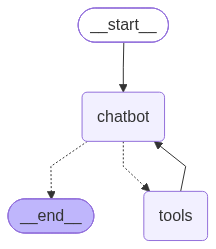

In [46]:
workflow

In [50]:
thread_id="1"
initial={'messages':[HumanMessage(content="who is asmar,use given pdf")]}
config={'configurable':{'thread_id':thread_id}}
final=workflow.invoke(initial,config=config)

In [48]:
final

{'messages': [HumanMessage(content='who is asmar', additional_kwargs={}, response_metadata={}, id='793d11b4-1a9b-4496-854c-55dc162aaf4a'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 239, 'prompt_tokens': 1436, 'total_tokens': 1675, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 192, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 1280, 'image_tokens': None, 'text_tokens': None}, 'latency_checkpoint': {'engine_tbt_ms': 7, 'engine_ttft_ms': 29, 'engine_ttlt_ms': 1979, 'pre_inference_ms': 188, 'service_tbt_ms': 7, 'service_ttft_ms': 1568, 'service_ttlt_ms': 3513, 'user_visible_ttft_ms': 1380}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Eclh0JsagXbGTH0ZqSh316gFuHsqx', 'service_tier': 'default', 'fini

In [51]:
final['messages'][-1].content

'From the PDF you gave (Asmar_Resume2026.pdf), "Asmar" is:\n\n- Name: Md Asmar  \n- Location: Bhubaneswar, Odisha  \n- Contact: +91 8825237173 | mdasmar719@gmail.com (LinkedIn and GitHub links listed)\n\nSummary / objective:\n- Computer Science undergraduate building AI-powered applications with LLMs and ML; seeking AI/ML or Software Engineering internships.\n\nEducation:\n- B.Tech, Computer Science & Engineering — KIIT (Kalinga Institute of Industrial Technology), Aug 2024 – Present. CGPA: 8.88/10.0\n\nExperience:\n- AI/ML Intern (Training Program), Kalinga Institute of Industrial Technology (May 2026 – July 2026). Hands-on ML/NLP work: data preprocessing, feature engineering, training/evaluation (regression, decision trees, random forest, KNN, Naive Bayes), TF-IDF and Bag-of-Words, Pandas, NumPy, Scikit-learn.\n\nKey projects (summaries from resume):\n- ZentroMart Chatbot (Oct 2026): Streamlit-based customer-support chatbot using Azure OpenAI, LangChain, ChromaDB, semantic search (Se

In [45]:
workflow.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='my name is asmar', additional_kwargs={}, response_metadata={}, id='810e82f4-7254-4a54-b780-419dc611c2e6'), AIMessage(content='Nice to meet you, Asmar. How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 88, 'prompt_tokens': 1381, 'total_tokens': 1469, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'latency_checkpoint': {'engine_tbt_ms': 6, 'engine_ttft_ms': 53, 'engine_ttlt_ms': 783, 'pre_inference_ms': 89, 'service_tbt_ms': 6, 'service_ttft_ms': 394, 'service_ttlt_ms': 1117, 'user_visible_ttft_ms': 304}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-

In [11]:
thread_id="1"
while True:
    inp=input("Enter your message:")
    initial={'messages':[HumanMessage(content=inp)]}
    if inp in ['exit','bye']:
        break
    config={'configurable':{'thread_id':thread_id}}
    final=workflow.invoke(initial,config=config)
    print(final['messages'][-1].content)

Hi — how can I help you today?


In [15]:
list(workflow.get_state_history(config=config))

[StateSnapshot(values={'messages': [HumanMessage(content='my name is asmar', additional_kwargs={}, response_metadata={}, id='4576a320-27b5-4cab-a560-012c2350870c'), AIMessage(content='Nice to meet you, Asmar! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 152, 'prompt_tokens': 11, 'total_tokens': 163, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 128, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'latency_checkpoint': {'engine_tbt_ms': 7, 'engine_ttft_ms': 57, 'engine_ttlt_ms': 1574, 'pre_inference_ms': 81, 'service_tbt_ms': 7, 'service_ttft_ms': 943, 'service_ttlt_ms': 2455, 'user_visible_ttft_ms': 862}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl

In [16]:
workflow.get_state({"configurable":{"thread_id":"1","checkpoint_id":"1f1cf759-5090-6ca9-8000-90b3c3c8ea9e"}})

StateSnapshot(values={'messages': [HumanMessage(content='my name is asmar', additional_kwargs={}, response_metadata={}, id='4576a320-27b5-4cab-a560-012c2350870c')]}, next=('chatbot',), config={'configurable': {'thread_id': '1', 'checkpoint_id': '1f1cf759-5090-6ca9-8000-90b3c3c8ea9e'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-10-24T06:38:54.371754+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1cf759-508e-6575-bfff-13c508db4848'}}, tasks=(PregelTask(id='fddbfe69-e1b7-d20e-264a-ef156fd86bd4', name='chatbot', path=('__pregel_pull', 'chatbot'), error=None, interrupts=(), state=None, result={'messages': AIMessage(content='Nice to meet you, Asmar! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 152, 'prompt_tokens': 11, 'total_tokens': 163, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_token

In [17]:
workflow.invoke(None,{"configurable":{"thread_id":"1","checkpoint_id":"1f1cf759-5090-6ca9-8000-90b3c3c8ea9e"}})

{'messages': [HumanMessage(content='my name is asmar', additional_kwargs={}, response_metadata={}, id='4576a320-27b5-4cab-a560-012c2350870c'),
  AIMessage(content='Nice to meet you, Asmar! How can I help you today — anything specific you need or want to talk about?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 98, 'prompt_tokens': 11, 'total_tokens': 109, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'latency_checkpoint': {'engine_tbt_ms': 7, 'engine_ttft_ms': 31, 'engine_ttlt_ms': 1113, 'pre_inference_ms': 77, 'service_tbt_ms': 7, 'service_ttft_ms': 388, 'service_ttlt_ms': 1464, 'user_visible_ttft_ms': 312}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_finger

In [18]:
workflow.update_state({"configurable":{"thread_id":"1","checkpoint_id":"1f1cf759-5090-6ca9-8000-90b3c3c8ea9e","checkpoint_ns":""}},{"message":"I am Saitama"})


{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1cf7b9-9e50-6074-8001-8b86c343a0b0'}}

In [20]:
from chatbot import workflow

for msg_chunk,meta in workflow.stream({"messages":[HumanMessage(content="what is agentic AI")]},config=config,stream_mode="messages"):
    if msg_chunk.content:
        print(msg_chunk.content,end=" ",flush=True)

Brief ly :  agent ic  AI  is  any  artificial  system  that  acts  autonom ously  in  an  environment  to  pursue  goals  —  not  just  answer  prompts .  It  perce ives ,  plans ,  chooses  and  executes  actions ,  and  often  adap ts  from  feedback .

 Key  elements 
 -  Goal -directed  behavior :  it  has  objectives  or  reward  signals  it  seeks  to  optimize .
 -  Aut onomy  and  decision -making :  it  chooses  actions  without  human  micro ‑ management .
 -  Ability  to  act  in  an  environment :  this  can  be  a  simulated  world ,  the  web ,  a  robot ,  or  APIs  and  files .
 -  Per ception ,  planning  and  learning :  it  gathers  information ,  plans  multi ‑ step  strategies ,  and  updates  behavior  from  outcomes .

 How  it  differs  from  ordinary  AI / LL Ms 
 -  Tool -like  models  respond  to  user  queries  and  stop .  Agent ic  systems  proactively  decide  next  steps ,  possibly  taking  sequences  of  actions  or  asking  for  resources .
 -  Exampl